In [1]:
!pip -q install -U diffusers transformers accelerate safetensors timm

In [2]:
import torch, json, re, time, random, os, math
import numpy as np, pandas as pd
from PIL import Image
from google.colab import drive
drive.mount('/content/drive')
ROOT = "/content/drive/MyDrive/agentic_t2i"; os.makedirs(ROOT, exist_ok=True)

from diffusers import StableDiffusionPipeline, DDIMScheduler
from diffusers.models.attention_processor import AttnProcessor2_0
dev = "cuda"
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16, safety_checker=None).to(dev)
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
for m in (pipe.unet, pipe.vae, pipe.text_encoder): m.requires_grad_(False)

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


In [3]:
OBJS = ["apple","banana","cup","bowl","chair","bottle","dog","cat","clock","vase","umbrella","backpack"]
COLORS = ["red","yellow","green","blue","purple","pink","brown","black","white"]
NUM = {2:"two",3:"three",4:"four"}
RELTXT = {"left of":"to the left of","right of":"to the right of","above":"above","below":"below"}
def art(w): return "an" if w[0] in "aeiou" else "a"
def O(n, c=1, col=None): return {"name":n,"word":n+("s" if c>1 else ""),"count":c,"color":col}

def build_prompts(n=10, seed=0):
    r = random.Random(seed); P = []
    for _ in range(n):
        o=r.choice(OBJS); c=r.choice([2,3,4])
        P.append(dict(cat="counting", prompt=f"a photo of {NUM[c]} {o}s", gt={"objects":[O(o,c)],"relations":[]}))
    for _ in range(n):
        o=r.choice(OBJS); col=r.choice(COLORS)
        P.append(dict(cat="color", prompt=f"a photo of {art(col)} {col} {o}", gt={"objects":[O(o,1,col)],"relations":[]}))
    for _ in range(n):
        a,b=r.sample(OBJS,2)
        P.append(dict(cat="two_objects", prompt=f"a photo of {art(a)} {a} and {art(b)} {b}", gt={"objects":[O(a),O(b)],"relations":[]}))
    for _ in range(n):
        a,b=r.sample(OBJS,2); rel=r.choice(list(RELTXT))
        P.append(dict(cat="position", prompt=f"a photo of {art(a)} {a} {RELTXT[rel]} {art(b)} {b}",
                      gt={"objects":[O(a),O(b)],"relations":[{"subject":a,"relation":rel,"object":b}]}))
    for _ in range(n):
        a,b=r.sample(OBJS,2); c1,c2=r.sample(COLORS,2)
        P.append(dict(cat="color_attr", prompt=f"a photo of {art(c1)} {c1} {a} and {art(c2)} {c2} {b}",
                      gt={"objects":[O(a,1,c1),O(b,1,c2)],"relations":[]}))
    return P

In [4]:
PFILE = f"{ROOT}/prompts_n20.json"
if os.path.exists(PFILE):
    PROMPTS = json.load(open(PFILE))
else:
    from transformers import AutoTokenizer, AutoModelForCausalLM
    ltok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct")
    llm = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct", torch_dtype=torch.float16).to(dev)
    SYS = """You convert an image prompt into JSON. Output ONLY JSON.
Schema: {"objects":[{"name":singular noun,"word":noun exactly as written in the prompt,"count":int,"color":string or null}],"relations":[{"subject":name,"relation":"left of"|"right of"|"above"|"below","object":name}]}
Prompt: a photo of three apples
{"objects":[{"name":"apple","word":"apples","count":3,"color":null}],"relations":[]}
Prompt: a photo of a red cup and a blue chair
{"objects":[{"name":"cup","word":"cup","count":1,"color":"red"},{"name":"chair","word":"chair","count":1,"color":"blue"}],"relations":[]}
Prompt: a photo of a dog to the left of a vase
{"objects":[{"name":"dog","word":"dog","count":1,"color":null},{"name":"vase","word":"vase","count":1,"color":null}],"relations":[{"subject":"dog","relation":"left of","object":"vase"}]}"""
    REL_OK = {"left of","right of","above","below"}

    def plan(prompt):
        msgs=[{"role":"system","content":SYS},{"role":"user","content":f"Prompt: {prompt}"}]
        text=ltok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        ids=ltok(text, return_tensors="pt").input_ids.to(dev)
        with torch.no_grad(): out=llm.generate(ids, max_new_tokens=220, do_sample=False)
        txt=ltok.decode(out[0, ids.shape[1]:], skip_special_tokens=True)
        try:
            p=json.loads(re.search(r"\{.*\}", txt, re.S).group(0))
            names=[o["name"] for o in p["objects"]]
            for o in p["objects"]:
                assert o["word"] in prompt
                o["count"]=int(o["count"])
                o["color"]=None if str(o.get("color")).lower() in ("none","null","") else o["color"]
            p["relations"]=p.get("relations",[])
            for r in p["relations"]:
                assert r["subject"] in names and r["object"] in names and r["relation"] in REL_OK
            return p
        except Exception:
            return {"objects":[],"relations":[]}

    PROMPTS = build_prompts(20)
    for p in PROMPTS: p["plan"] = plan(p["prompt"])
    json.dump(PROMPTS, open(PFILE,"w"))
    del llm; torch.cuda.empty_cache()

def same(p,g):
    f=lambda x:(sorted(((o["name"],o["count"],o["color"]) for o in x["objects"]),key=str),
                sorted(((r["subject"],r["relation"],r["object"]) for r in x["relations"]),key=str))
    return f(p)==f(g)
print("planner accuracy:", np.mean([same(x["plan"],x["gt"]) for x in PROMPTS]), "| prompts:", len(PROMPTS))
print(len(PROMPTS), "plan" in PROMPTS[0])

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

planner accuracy: 1.0 | prompts: 100
100 True


In [5]:
REG = {"left of":((0,.1,.5,.9),(.5,.1,1,.9)), "right of":((.5,.1,1,.9),(0,.1,.5,.9)),
       "above":((.1,0,.9,.5),(.1,.5,.9,1)),  "below":((.1,.5,.9,1),(.1,0,.9,.5))}
def make_layout(plan):
    objs=plan["objects"]; names=[o["name"] for o in objs]; n=len(objs)
    reg={i:(i/n,0.1,(i+1)/n,0.9) for i in range(n)}
    for r in plan["relations"]:
        s,o=names.index(r["subject"]),names.index(r["object"])
        reg[s],reg[o]=REG[r["relation"]]
    boxes={}
    for i,o in enumerate(objs):
        x0,y0,x1,y1=reg[i]; c=max(1,o["count"]); w=(x1-x0)/c
        boxes[i]=[(x0+k*w+.03,y0+.03,x0+(k+1)*w-.03,y1-.03) for k in range(c)]
    return boxes

In [6]:
class Store:
    active=False; maps={}
    def reset(self): self.maps={}
store=Store()

class Proc:
    def __init__(self): self.default=AttnProcessor2_0()
    def __call__(self, attn, hidden_states, encoder_hidden_states=None, attention_mask=None, **kw):
        if encoder_hidden_states is None or not store.active:
            return self.default(attn, hidden_states, encoder_hidden_states, attention_mask, **kw)
        q=attn.head_to_batch_dim(attn.to_q(hidden_states))
        k=attn.head_to_batch_dim(attn.to_k(encoder_hidden_states))
        v=attn.head_to_batch_dim(attn.to_v(encoder_hidden_states))
        probs=attn.get_attention_scores(q,k,None)
        res=int(math.sqrt(hidden_states.shape[1]))
        if res in (16,32): store.maps.setdefault(res,[]).append(probs)
        out=attn.batch_to_head_dim(torch.bmm(probs,v))
        return attn.to_out[1](attn.to_out[0](out))
pipe.unet.set_attn_processor(Proc())

def tok_idx(prompt, word):
    ids=pipe.tokenizer(prompt).input_ids
    w=pipe.tokenizer(word, add_special_tokens=False).input_ids
    for s in range(len(ids)-len(w)+1):
        if ids[s:s+len(w)]==w: return s+len(w)-1
    return None

def box_mask(b,res):
    m=torch.zeros(res,res,device=dev); x0,y0,x1,y1=b
    ya,yb=int(y0*res),max(int(y0*res)+1,math.ceil(y1*res))
    xa,xb=int(x0*res),max(int(x0*res)+1,math.ceil(x1*res))
    m[ya:yb,xa:xb]=1; return m.flatten()

def layout_loss(spec):
    total=0.
    for res in (16,32):
        A=torch.stack(store.maps[res]).float().mean((0,1))
        for s in spec:
            masks=[box_mask(b,res) for b in s["boxes"]]
            union=torch.clamp(sum(masks),max=1); c=len(masks)
            for t in s["tok"]:
                a=A[:,t]; a=a/(a.sum()+1e-8)
                l=1-(a*union).sum()
                if c>1:
                    l=l+s["lam"]*sum(torch.relu(0.8/c-(a*m).sum()) for m in masks)
                total=total+s["w"]*l
    return total

def guide(lat,t,cond,spec,alpha):
    lat=lat.float().detach().requires_grad_(True)
    store.reset(); store.active=True
    pipe.unet(lat.half(), t, encoder_hidden_states=cond)
    store.active=False
    loss=layout_loss(spec)
    g=torch.autograd.grad(loss*1024, lat)[0]/1024
    store.reset()
    if not torch.isfinite(g).all(): return lat.detach().half()
    return (lat-alpha*g).detach().half()

def build_spec(prompt, plan, boost=None):
    boxes=make_layout(plan); spec=[]
    for i,o in enumerate(plan["objects"]):
        t=tok_idx(prompt,o["word"])
        if t is None: continue
        toks=[t]; w=1.0; lam=0.5; b=boost.get(i) if boost else None
        if b:
            w=b["scale"]; lam=1.5
            if b["color"] and o["color"]:
                ct=tok_idx(prompt,o["color"])
                if ct is not None: toks.append(ct)
        spec.append({"tok":toks,"boxes":boxes[i],"w":w,"lam":lam})
    return spec

@torch.no_grad()
def embed(text):
    ids=pipe.tokenizer(text,padding="max_length",max_length=77,truncation=True,return_tensors="pt").input_ids.to(dev)
    return pipe.text_encoder(ids)[0]

def generate(prompt, spec=None, seed=0, steps=30, cfg=7.5, guide_steps=15, alpha=30.):
    g=torch.Generator(dev).manual_seed(seed)
    lat=torch.randn((1,4,64,64),generator=g,device=dev,dtype=torch.float16)
    cond,unc=embed(prompt),embed("")
    pipe.scheduler.set_timesteps(steps,device=dev)
    for i,t in enumerate(pipe.scheduler.timesteps):
        if spec and i<guide_steps:
            lat=guide(lat,t,cond,spec,alpha*(1-0.5*i/guide_steps))
        with torch.no_grad():
            eps=pipe.unet(torch.cat([lat,lat]),t,encoder_hidden_states=torch.cat([unc,cond])).sample
            eu,ec=eps.chunk(2); eps=eu+cfg*(ec-eu)
            lat=pipe.scheduler.step(eps,t,lat).prev_sample
    with torch.no_grad():
        img=pipe.vae.decode(lat/pipe.vae.config.scaling_factor).sample
    img=((img/2+0.5).clamp(0,1)[0].permute(1,2,0).float().cpu().numpy()*255).astype("uint8")
    return Image.fromarray(img)

In [7]:
from transformers import Owlv2Processor, Owlv2ForObjectDetection, CLIPModel, CLIPProcessor
from torchvision.ops import nms
owl_p=Owlv2Processor.from_pretrained("google/owlv2-base-patch16-ensemble")
owl=Owlv2ForObjectDetection.from_pretrained("google/owlv2-base-patch16-ensemble").to(dev).eval()
clip_b=CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
clip_bp=CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

@torch.no_grad()
def clip_color(clip, proc, crop, name):
    x=proc(text=[f"a photo of a {c} {name}" for c in COLORS], images=crop, return_tensors="pt", padding=True).to(dev)
    x["pixel_values"]=x["pixel_values"].to(clip.dtype)
    return COLORS[clip(**x).logits_per_image.argmax(-1).item()]

def rel_ok(bs,bo,rel,size):
    cs=((bs[0]+bs[2])/2,(bs[1]+bs[3])/2); co=((bo[0]+bo[2])/2,(bo[1]+bo[3])/2); m=0.1*size[0]
    return {"left of":cs[0]<co[0]-m,"right of":cs[0]>co[0]+m,"above":cs[1]<co[1]-m,"below":cs[1]>co[1]+m}[rel]

@torch.no_grad()
def owl_detect(img, names, thr=0.3):
    x = owl_p(text=[[f"a photo of a {n}" for n in names]], images=img, return_tensors="pt").to(dev)
    out = owl(**x)
    pp = getattr(owl_p, "post_process_object_detection", None) or owl_p.image_processor.post_process_object_detection
    r = pp(out, threshold=thr, target_sizes=torch.tensor([[max(img.size)] * 2], device=out.logits.device))[0]
    res = {}
    for i, n in enumerate(names):
        m = r["labels"] == i
        b, s = r["boxes"][m], r["scores"][m]
        keep = nms(b, s, 0.5) if len(b) else []
        res[n] = [b[k].tolist() for k in keep]
    return res

preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

... (12 outputs left out)

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

In [8]:
@torch.no_grad()
def clip_color_probs(clip, proc, crop, name):
    x=proc(text=[f"a photo of a {c} {name}" for c in COLORS], images=crop, return_tensors="pt", padding=True).to(dev)
    x["pixel_values"]=x["pixel_values"].to(clip.dtype)
    return clip(**x).logits_per_image.softmax(-1)[0].float().cpu().numpy()

def rel_dist(bs,bo,rel,W):
    cs=((bs[0]+bs[2])/2,(bs[1]+bs[3])/2); co=((bo[0]+bo[2])/2,(bo[1]+bo[3])/2)
    return {"left of":co[0]-cs[0],"right of":cs[0]-co[0],"above":co[1]-cs[1],"below":cs[1]-co[1]}[rel]/W

def verify(img, plan):
    objs=plan["objects"]
    if not objs: return {"score":0.0,"fails":[],"invalid":True}      # khali plan = failure
    names=[o["name"] for o in objs]; det=owl_detect(img,names); W=img.size[0]
    checks=[]; fails=[]
    for i,o in enumerate(objs):
        d=det[o["name"]]; ok=len(d)==o["count"]; checks.append(ok)
        if not ok: fails.append((i,"count",min(1.0,abs(len(d)-o["count"])/o["count"])))
        if o["color"]:
            ci=COLORS.index(o["color"]) if o["color"] in COLORS else None
            if d and ci is not None:
                ps=[clip_color_probs(clip_b,clip_bp,img.crop(tuple(b)),o["name"]) for b in d]
                ok=all(p.argmax()==ci for p in ps); sev=1-float(np.mean([p[ci] for p in ps]))
            else: ok=False; sev=1.0
            checks.append(ok)
            if not ok: fails.append((i,"color",sev))
    for r in plan["relations"]:
        s,o=names.index(r["subject"]),names.index(r["object"])
        ds,do=det[names[s]],det[names[o]]
        if ds and do:
            dist=rel_dist(ds[0],do[0],r["relation"],W); ok=dist>0.1
            sev=float(np.clip((0.1-dist)/0.5,0.05,1.0))
        else: ok=False; sev=1.0
        checks.append(ok)
        if not ok: fails += [(s,"pos",sev),(o,"pos",sev)]
    return {"score":float(np.mean(checks)),"fails":fails,"invalid":False}

In [9]:
CFG = {
 "bon":          dict(layout=False, refine=False),
 "reseed":       dict(layout=True,  refine=False),
 "ours":         dict(layout=True,  refine=True, adapt=True,  color=True),
 "ours_fixed":   dict(layout=True,  refine=True, adapt=False, color=True),   # ablation
 "ours_nocolor": dict(layout=True,  refine=True, adapt=True,  color=False),  # ablation
}
KMAX=5; STEP=2.0

def run2(method, idx, item, sid):
    c=CFG[method]; prompt,pl=item["prompt"],item["plan"]; t0=time.time()
    s0=7919*sid+idx; boost={}; vs=[]; invalid=False
    d=f"{ROOT}/out/{method}"; os.makedirs(d,exist_ok=True)
    for k in range(KMAX):
        seed = s0 if c["refine"] else s0+100000*k          # ours: wohi noise; baselines: naya noise
        spec = build_spec(prompt,pl,boost or None) if c["layout"] else None
        img=generate(prompt,spec,seed)
        img.save(f"{d}/{idx}_s{sid}_a{k}.png")
        v=verify(img,pl); vs.append(v["score"]); invalid=v.get("invalid",False)
        if v["score"]==1.0 or invalid: break
        if c["refine"]:
            for i,typ,sev in v["fails"]:
                b=boost.setdefault(i,{"scale":1.0,"color":False})
                b["scale"]+= STEP*(0.5+sev) if c["adapt"] else STEP
                if typ=="color" and c["color"]: b["color"]=True
    return dict(method=method,idx=idx,sid=sid,gens=len(vs),time=time.time()-t0,vs=vs,invalid=invalid)

RF=f"{ROOT}/rows_v2.json"
rows=json.load(open(RF)) if os.path.exists(RF) else []
done={(r["method"],r["idx"],r["sid"]) for r in rows}
def run_all(methods, sids, idxs):
    for sid in sids:
        for method in methods:
            for idx in idxs:
                if (method,idx,sid) in done: continue
                rows.append(run2(method,idx,PROMPTS[idx],sid)); done.add((method,idx,sid))
                json.dump(rows,open(RF,"w"))
            print("seed",sid,method,"done")

print("invalid plans:", sum(len(x["plan"]["objects"])==0 for x in PROMPTS), "/", len(PROMPTS))

invalid plans: 0 / 100


In [10]:
run_all(["bon","reseed","ours"], sids=[0], idxs=range(len(PROMPTS)))

seed 0 bon done
seed 0 reseed done
seed 0 ours done


In [11]:
import gc
from transformers import DetrConfig, DetrForObjectDetection, DetrImageProcessor

for name in ["pipe", "owl", "clip_b"]:
    globals().pop(name, None)
gc.collect(); torch.cuda.empty_cache()

detr_p = DetrImageProcessor.from_pretrained("facebook/detr-resnet-101")
cfg = DetrConfig.from_pretrained("facebook/detr-resnet-101")
cfg.use_pretrained_backbone = False
detr = DetrForObjectDetection.from_pretrained("facebook/detr-resnet-101", config=cfg).to(dev).eval()
clip_l = CLIPModel.from_pretrained("openai/clip-vit-large-patch14", torch_dtype=torch.float16).to(dev).eval()
clip_lp = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14")

@torch.no_grad()
def detr_detect(img, thr=0.7):
    x = detr_p(images=img, return_tensors="pt").to(dev)
    r = detr_p.post_process_object_detection(detr(**x), threshold=thr, target_sizes=[img.size[::-1]])[0]
    res = {}
    for s, l, b in zip(r["scores"], r["labels"], r["boxes"]):
        res.setdefault(detr.config.id2label[l.item()], []).append((float(s), b.tolist()))
    return {k: [b for _, b in sorted(v, key=lambda z: -z[0])] for k, v in res.items()}

def gt_check(img, gt):
    det = detr_detect(img); ok = []
    for o in gt["objects"]:
        d = det.get(o["name"], [])
        ok.append(len(d) == o["count"])
        if o["color"]:
            cols = [clip_color(clip_l, clip_lp, img.crop(tuple(b)), o["name"]) for b in d]
            ok.append(len(d) > 0 and all(c == o["color"] for c in cols))
    for r in gt["relations"]:
        ds, do = det.get(r["subject"], []), det.get(r["object"], [])
        ok.append(bool(ds and do) and rel_ok(ds[0], do[0], r["relation"], (512, 512)))
    return all(ok)

# ---------- evaluation ----------
RF=f"{ROOT}/rows_v2.json"; rows=json.load(open(RF))
assert len(rows) > 0, "rows khali hai! Pehle run cells chalao."
cache={}
def ok_img(method,idx,sid,a):
    key=(method,idx,sid,a)
    if key not in cache:
        img=Image.open(f"{ROOT}/out/{method}/{idx}_s{sid}_a{a}.png").convert("RGB")
        cache[key]=gt_check(img,PROMPTS[idx]["gt"])
    return cache[key]

recs=[]
for r in rows:
    item=PROMPTS[r["idx"]]
    for K in [1,2,3,5]:
        a=int(np.argmax(r["vs"][:K]))
        recs.append(dict(method=r["method"],sid=r["sid"],idx=r["idx"],cat=item["cat"],K=K,
                         ok=ok_img(r["method"],r["idx"],r["sid"],a),gens=min(r["gens"],K)))
df=pd.DataFrame(recs); df.to_csv(f"{ROOT}/eval_v2.csv",index=False)

def ms(d,by):
    per=d.groupby(by+["sid"]).ok.mean().reset_index()
    return per.groupby(by).ok.agg(["mean","std"]).round(3)

print("=== Accuracy vs K (mean/std over seeds) ===");  print(ms(df,["method","K"]))
print("\n=== Per category (K=3) ===")
print(df[df.K==3].groupby(["method","cat","sid"]).ok.mean().reset_index()
        .groupby(["method","cat"]).ok.mean().unstack().round(3))
R=pd.DataFrame(rows)
print("\n=== Cost ===");  print(R.groupby("method")[["gens","time"]].mean().round(2))
print("invalid plans:", int(R.invalid.sum()))

def paired(a,b,K=3):
    x=df[(df.method==a)&(df.K==K)].set_index(["idx","sid"]).ok
    y=df[(df.method==b)&(df.K==K)].set_index(["idx","sid"]).ok
    j=pd.concat([x,y],axis=1,keys=["a","b"]).dropna().astype(bool)
    print(f"{a} vs {b} (K={K}): sirf {a} jeeta={int((j.a&~j.b).sum())}, sirf {b} jeeta={int((~j.a&j.b).sum())}, "
          f"dono={int((j.a&j.b).sum())}, koi nahi={int((~j.a&~j.b).sum())}")
print("\n=== Paired comparison ===")
paired("ours","reseed"); paired("ours","bon")

vr=[(s==1.0, ok_img(r["method"],r["idx"],r["sid"],a)) for r in rows for a,s in enumerate(r["vs"])]
v=pd.DataFrame(vr,columns=["verifier_pass","evaluator_pass"])
print("\n=== Verifier reliability ==="); print(pd.crosstab(v.verifier_pass,v.evaluator_pass))

preprocessor_config.json:   0%|          | 0.00/255 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.38k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  243MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/785 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-101
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (7 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

=== Accuracy vs K (mean/std over seeds) ===
          mean  std
method K           
bon    1  0.32  NaN
       2  0.36  NaN
       3  0.39  NaN
       5  0.42  NaN
ours   1  0.42  NaN
       2  0.42  NaN
       3  0.44  NaN
       5  0.44  NaN
reseed 1  0.40  NaN
       2  0.44  NaN
       3  0.47  NaN
       5  0.47  NaN

=== Per category (K=3) ===
cat     color  color_attr  counting  position  two_objects
method                                                    
bon      0.65        0.10      0.60      0.15         0.45
ours     0.50        0.25      0.65      0.40         0.40
reseed   0.55        0.25      0.65      0.35         0.55

=== Cost ===
        gens   time
method             
bon     2.77  16.51
ours    2.40  21.20
reseed  2.23  19.74
invalid plans: 0

=== Paired comparison ===
ours vs reseed (K=3): sirf ours jeeta=6, sirf reseed jeeta=9, dono=38, koi nahi=47
ours vs bon (K=3): sirf ours jeeta=22, sirf bon jeeta=17, dono=22, koi nahi=39

=== Verifier reliability ===
eva

a photo of a red dog and a black cup ['dog', 'laptop', 'cup']


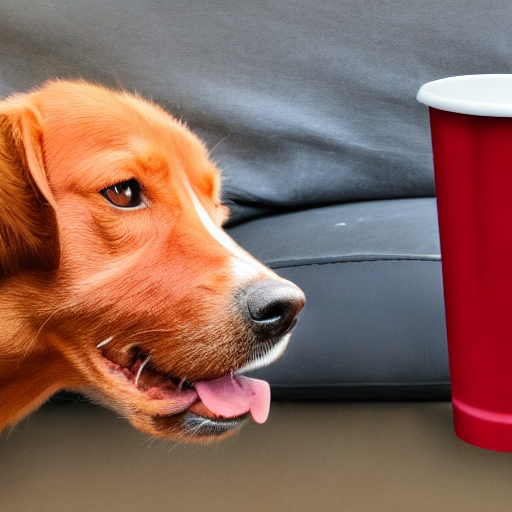

a photo of a yellow apple and a brown vase ['vase', 'apple']


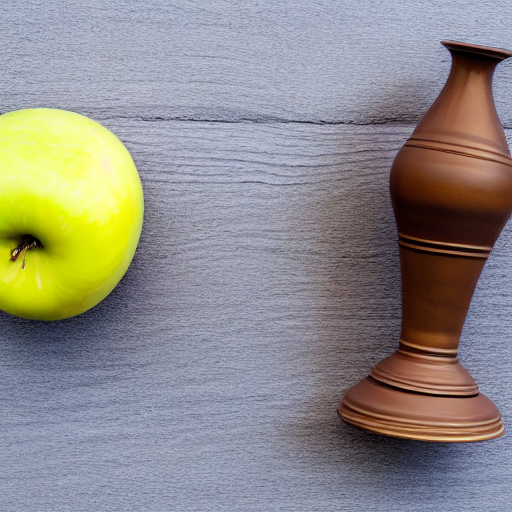

a photo of a pink bowl and a black chair ['chair', 'bowl']


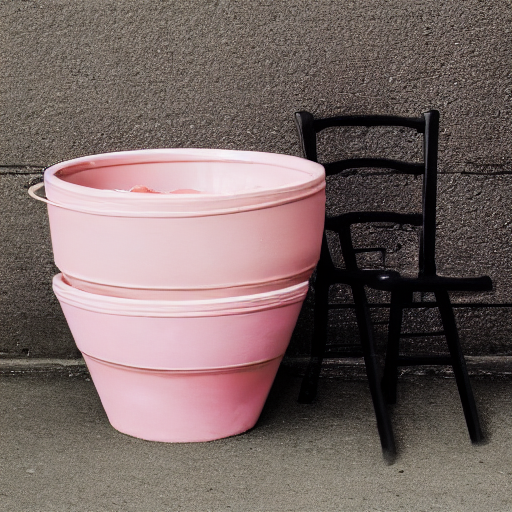

a photo of a blue vase and a red cup ['dining table', 'vase', 'potted plant']


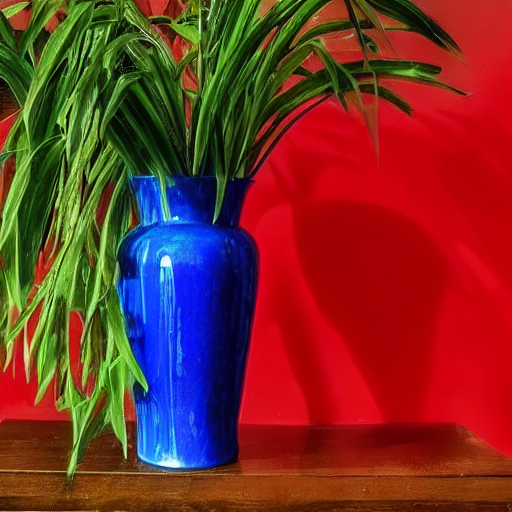

In [12]:
for i in [i for i,p in enumerate(PROMPTS) if p["cat"]=="color_attr"][:4]:
    img=Image.open(f"{ROOT}/out/ours/{i}_s0_a0.png"); print(PROMPTS[i]["prompt"], list(detr_detect(img).keys())); display(img)